In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [2]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [3]:
class Value:
    def __init__(self, data, _children=(), _op = '', label=''):
        self.data = data
        self.grad = 0.0
        self._backward = lambda: None
        # these two attr are used for building graphs
        self._prev = set(_children)
        self._op = _op
        self.label = label

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        out = Value(self.data + other.data, (self, other), _op='+')

        def _backward():
            # dx/dself = dx/dout * dout/dself = out.grad * 1.0
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad
        out._backward = _backward
        return out

    def __mul__(self, other):
        out = Value(self.data * other.data, (self, other), _op='*')

        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward = _backward
        return out

    def tanh(self):
        x = self.data
        t = (math.exp(2*x) - 1) / (math.exp(2*x) + 1)
        out = Value(t, (self, ), 'tanh')

        def _backward():
            self.grad += (1 - t**2) * out.grad
        out._backward = _backward
        return out

    def backward(self):

        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)
        
        self.grad = 1.0
        for node in reversed(topo):
            node._backward()


a = Value(-4.0, label='a')
b = Value(2.0, label='b')
c = Value(10.0, label='c')
e = a*b; e.label='e'
d = e + c; d.label='d'
f = Value(-2.0, label='f')
L = d * f; L.label='L'
L

Value(data=-4.0)

In [4]:
L._prev

{Value(data=-2.0), Value(data=2.0)}

In [5]:
L._op

'*'

In [6]:
from graphviz import Digraph

def trace(root):
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root):
    dot = Digraph(
        format='svg',
        graph_attr={'rankdir': 'LR'} # LR --> left to right
    )

    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        # for any value in the graph, create a rectangular ('record') node for it
        dot.node(
            name = uid,
            label = "{%s | data %.4f | grad %.4f}" % (n.label, n.data, n.grad),
            shape='record'
        )
        if n._op:
            # if this value is a result of some operation, 
            # create an op node for it
            dot.node(
                name = uid + n._op,
                label = n._op
            )
            # and connecr this node to it
            dot.edge(uid + n._op, uid)

    for n1, n2 in edges:
        # connect n1 to the op node of n2
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot

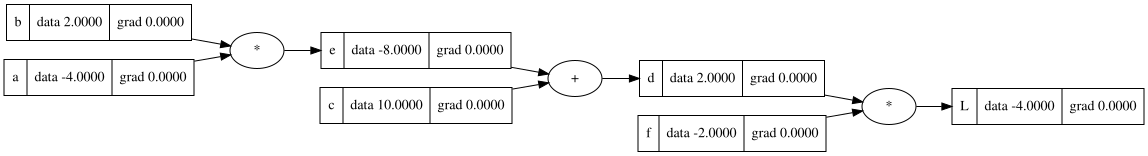

In [7]:
draw_dot(L)

In [8]:
# for L to increase , we need to go in the direction of gradiant

a.data += 0.01 * a.grad
b.data += 0.01 * b.grad
c.data += 0.01 * c.grad
f.data += 0.01 * f.grad

e = a * b
d = e + c
L = d * f

print(L.data) # we will see an increase in L

-4.0


w.k.t

L = d * f


dL/dd = f --> d.grad = f = -2.0

dL/df = d --> f.grad = d = 2.0

==============================

d = e + c


dd / dc = ? = 1.0

dd / de = ? = 1.0

=============================

dL / dc = (dL / dd) * (dd / dc) --> (-2.0) * (1.0) = -2.0 --> c.grad

dL / de = (dL / dd) * (dd / de) --> (-2.0) * (1.0) = -2.0 --> e.grad


=============================

dL/ da = ?

L --> d --> e --> a

dl / da = (dL / dd) * (dd / de) * (de / da)

KNOWN:

dL/dd, dL/de

UKNOWN:

de/da

e = a*b

de/da = ? = b --> 2.0

dL / da = -2.0 * 1.0 * 2.0 --> a.grad = -4.0


dL / db = ?

L --> d --> e --> b

dL / db - (dL / dd) * (dd / de) * (de / db)

de / db = ? --> a --> -4.0

dL / db = -2.0 * 1.0 * -4.0 --> b.grad = 8.0


In [9]:
L.grad = 1.0
d.grad = -2.0
f.grad = 2.0
c.grad = -2.0
e.grad = -2.0
a.grad = -4.0
b.grad = 8.0

In [10]:
def lol():
    h = 0.001
    
    a = Value(-4.0, label='a')
    b = Value(2.0, label='b')
    c = Value(10.0, label='c')
    e = a*b; e.label='e'
    d = e + c; d.label='d'
    f = Value(-2.0, label='f')
    L = d * f; L.label='L'
    L1 = L.data

    a = Value(-4.0, label='a')
    # a.data += h
    b = Value(2.0, label='b')
    b.data += h
    c = Value(10.0, label='c')
    e = a*b; e.label='e'
    d = e + c; d.label='d'
    f = Value(-2.0, label='f')
    L = d * f; L.label='L'
    L2 = L.data

    print((L2 - L1)/h)

lol()

7.999999999999119


In [11]:
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')

# weights w1, w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')

#bias of the neuron
b = Value(6.881375070195432, label='b')

x1w1 = x1*w1; x1w1.label = 'x1w1'
x2w2 = x2*w2; x2w2.label='x2w2'

x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1w1x2w2'
n = x1w1x2w2 + b; n.label='n'

o = n.tanh(); o.label='o'

In [12]:
o.backward()

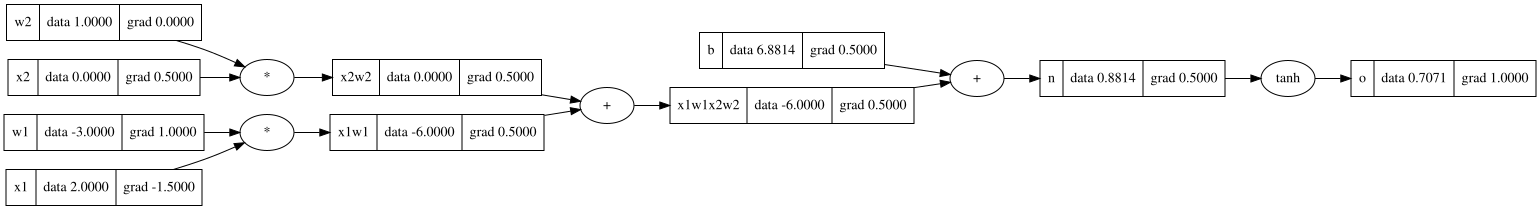

In [13]:
draw_dot(o)

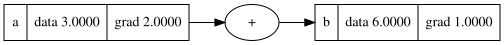

In [14]:
a = Value(3.0, label='a')
b = a + a; b.label = 'b'

b.backward()
draw_dot(b)

# here a.grad = 2 but it is 1.0 as the value is being overwriiten
# for that we need to accumulate the value which wil be
# self.grad += 1.0 * out.grad